# Vehicle Insurance Fraud Detection
- data: kaggle `shivamb/vehicle-claim-fraud-detection` (15,420 claims, ~6% fraud)
- goal: flag claims worth investigating - balance missed fraud against investigation cost
- cost assumptions (NOT in the data): $15K avg fraud payout, $250 per investigation
- model selection + threshold choice use the training set only (CV). test set is scored once at the end
- results + caveats are in the README

Imports

In [ ]:
%pip install -r requirements.txt

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
import kagglehub
import os

os.makedirs('outputs', exist_ok=True)

Load data

In [6]:
path = kagglehub.dataset_download("shivamb/vehicle-claim-fraud-detection")

csv_files = sorted(f for f in os.listdir(path) if f.lower().endswith(".csv"))
if not csv_files:
    raise FileNotFoundError("No CSV found in downloaded dataset directory.")

df = pd.read_csv(os.path.join(path, csv_files[0]))
print(f"Loaded: {csv_files[0]} | {df.shape[0]} rows x {df.shape[1]} columns")

Loaded: fraud_oracle.csv | 15420 rows x 33 columns


Check out the data

In [7]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Month                 15420 non-null  object
 1   WeekOfMonth           15420 non-null  int64 
 2   DayOfWeek             15420 non-null  object
 3   Make                  15420 non-null  object
 4   AccidentArea          15420 non-null  object
 5   DayOfWeekClaimed      15420 non-null  object
 6   MonthClaimed          15420 non-null  object
 7   WeekOfMonthClaimed    15420 non-null  int64 
 8   Sex                   15420 non-null  object
 9   MaritalStatus         15420 non-null  object
 10  Age                   15420 non-null  int64 
 11  Fault                 15420 non-null  object
 12  PolicyType            15420 non-null  object
 13  VehicleCategory       15420 non-null  object
 14  VehiclePrice          15420 non-null  object
 15  FraudFound_P          15420 non-null

,WeekOfMonth,WeekOfMonthClaimed,Age,FraudFound_P,PolicyNumber,RepNumber,Deductible,DriverRating,Year
count,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000
mean,2.788586,2.693969,39.855707,0.059857,7710.500000,8.483268,407.704280,2.487808,1994.866472
std,1.287585,1.259115,13.492377,0.237230,4451.514911,4.599948,43.950998,1.119453,0.803313
min,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,300.000000,1.000000,1994.000000
25%,2.000000,2.000000,31.000000,0.000000,3855.750000,5.000000,400.000000,1.000000,1994.000000
50%,3.000000,3.000000,38.000000,0.000000,7710.500000,8.000000,400.000000,2.000000,1995.000000
75%,4.000000,4.000000,48.000000,0.000000,11565.250000,12.000000,400.000000,3.000000,1996.000000
max,5.000000,5.000000,80.000000,1.000000,15420.000000,16.000000,700.000000,4.000000,1996.000000


Check for nulls and duplicates

In [8]:
print(f"Nulls: {df.isnull().sum().sum()}")
print(f"Duplicates: {df.duplicated().sum()}")
# zero of both

Nulls: 0
Duplicates: 0


ID columns
- policynumber looks like a row id - checking before it goes anywhere near the model

In [9]:
print("PolicyNumber unique:", df['PolicyNumber'].is_unique)
print("PolicyNumber is just 1..n:", (df['PolicyNumber'] == np.arange(1, len(df) + 1)).all())

# policynumber = row id, dropping it so the model can't memorize rows
# repnumber (1-16) is a rep id - testing it with CV below instead of assuming

PolicyNumber unique: True
PolicyNumber is just 1..n: True


Outlier check on numeric cols

In [10]:
# skipping the target + id - iqr doesn't mean anything on a 0/1 flag or a row counter
numeric_cols = [c for c in df.select_dtypes(include=[np.number]).columns
                if c not in ['FraudFound_P', 'PolicyNumber']]

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = len(df[(df[col] < lower) | (df[col] > upper)])
    if n_outliers > 0:
        print(f"{col}: {n_outliers} outliers ({n_outliers/len(df)*100:.1f}%)")

# only deductible and age have outliers - leaving both, nothing looks like bad data

Age: 547 outliers (3.5%)
Deductible: 582 outliers (3.8%)


Age versus fraud

In [11]:
print("Rows with age 0:       ", (df['Age'] == 0).sum())
print("Fraud rate for age 0:   ", f"{df[df['Age'] == 0]['FraudFound_P'].mean():.2%}")
print("Fraud rate age != 0:    ", f"{df[df['Age'] != 0]['FraudFound_P'].mean():.2%}")
print("Fraud rate under 21:    ", f"{df[df['Age'] < 21]['FraudFound_P'].mean():.2%}")
print("Fraud rate 21+:         ", f"{df[df['Age'] >= 21]['FraudFound_P'].mean():.2%}")

# is the age 0 gap real or just noise?
ct = pd.crosstab(df['Age'] == 0, df['FraudFound_P'])
chi2, p, _, _ = chi2_contingency(ct)
print(f"Chi-square p-value (age 0 vs fraud): {p:.4f}")

# gap is statistically real (p < 0.01) but it's only 320 rows
# age 0 is most likely a missing-value placeholder (nobody files a claim at age 0)
# leaving it in - not calling it a real fraud signal

Rows with age 0:        320
Fraud rate for age 0:    9.69%
Fraud rate age != 0:     5.91%
Fraud rate under 21:     11.06%
Fraud rate 21+:          5.84%
Chi-square p-value (age 0 vs fraud): 0.0069


Age distribution plots

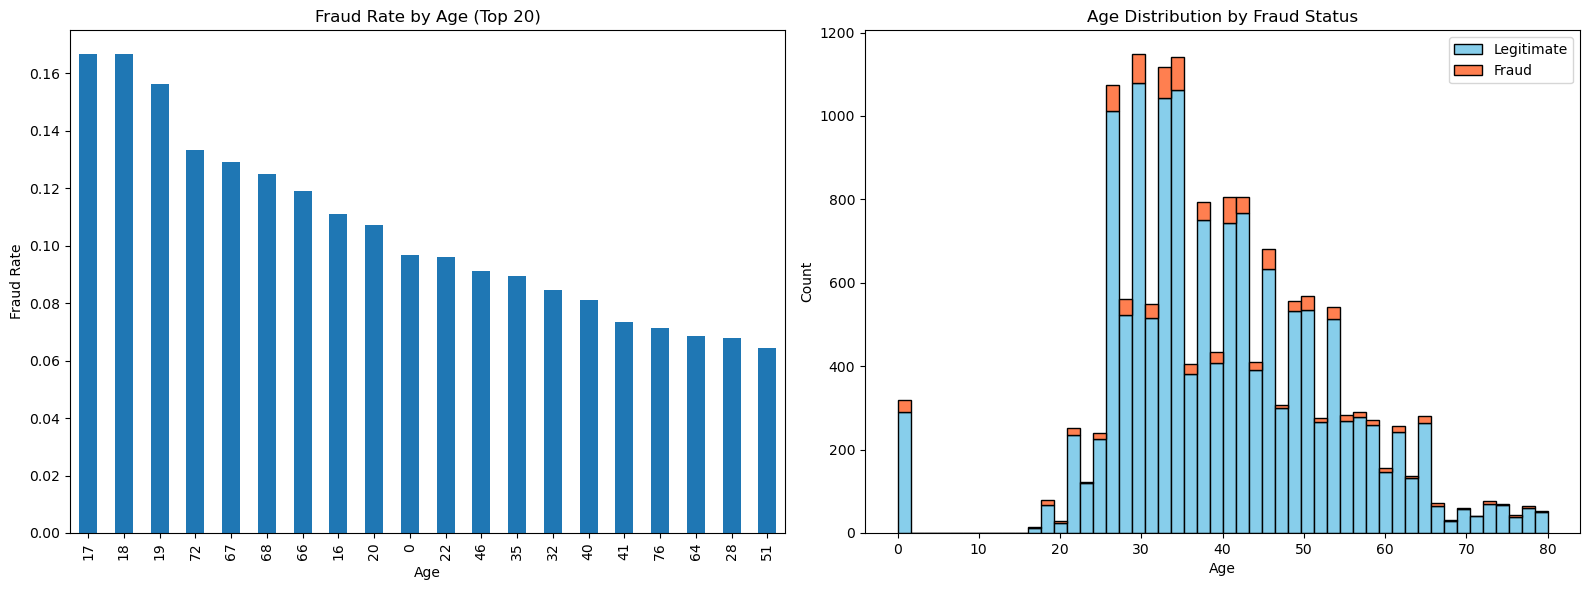

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

fraud_by_age = df.groupby('Age')['FraudFound_P'].mean().sort_values(ascending=False).head(20)
fraud_by_age.plot(kind='bar', ax=axes[0])
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Fraud Rate')
axes[0].set_title('Fraud Rate by Age (Top 20)')

fraud_ages = df[df['FraudFound_P'] == 1]['Age']
legit_ages = df[df['FraudFound_P'] == 0]['Age']
axes[1].hist([legit_ages, fraud_ages], bins=50, edgecolor='black',
             label=['Legitimate', 'Fraud'], color=['skyblue', 'coral'], stacked=True)
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Count')
axes[1].set_title('Age Distribution by Fraud Status')
axes[1].legend()

plt.tight_layout()
plt.show()

Train / test split
- policynumber dropped here (row id)

In [13]:
DROP_COLS = ['PolicyNumber']

def prepare_data(dataframe):
    X = dataframe.drop(['FraudFound_P'] + DROP_COLS, axis=1)
    y = dataframe['FraudFound_P']
    return train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

X_train, X_test, y_train, y_test = prepare_data(df)

# same folds for every cv call below
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Fraud rate - train: {y_train.mean():.2%}, test: {y_test.mean():.2%}")

Train: (10794, 31), Test: (4626, 31)
Fraud rate - train: 5.98%, test: 5.99%


Preprocessing

In [14]:
# dense=True is only for hist gradboost - it can't take sparse input
def make_preprocess(X, scale_numeric=False, dense=False):
    num = X.select_dtypes(include=[np.number]).columns
    cat = X.select_dtypes(exclude=[np.number]).columns
    return ColumnTransformer(transformers=[
        ('num', StandardScaler() if scale_numeric else 'passthrough', num),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=not dense), cat)
    ])

preprocess = make_preprocess(X_train)

# class imbalance ratio - ~6% fraud
scale_pos_weight = len(y_train[y_train == 0]) / len(y_train[y_train == 1])
print(f"Class ratio (legit:fraud): {scale_pos_weight:.1f}:1")

# two xgboost configs - v1 is the original, v2 is heavier regularization
xgb_v1 = dict(
    random_state=42, eval_metric='logloss',
    n_estimators=150, max_depth=5, learning_rate=0.1,
    subsample=0.9, colsample_bytree=0.8,
    reg_alpha=1, reg_lambda=1, min_child_weight=5
)
xgb_v2 = dict(
    random_state=42, eval_metric='logloss',
    n_estimators=100, max_depth=4, learning_rate=0.1,
    subsample=0.8, colsample_bytree=0.8,
    reg_alpha=2, reg_lambda=2, min_child_weight=20
)

Class ratio (legit:fraud): 15.7:1


ID check with CV
- does dropping policynumber / repnumber change the score?
- (xgb_v2, 5-fold CV on train only)

In [15]:
id_tests = {
    'all features':                  [],
    'drop PolicyNumber':             ['PolicyNumber'],
    'drop PolicyNumber + RepNumber': ['PolicyNumber', 'RepNumber'],
    'drop PolicyNumber + RepNumber + Year': ['PolicyNumber', 'RepNumber', 'Year'],
}

X_train_full = df.loc[X_train.index].drop('FraudFound_P', axis=1)

for name, drop in id_tests.items():
    X_tmp = X_train_full.drop(columns=drop)
    pipe = Pipeline([
        ('prep', make_preprocess(X_tmp)),
        ('model', XGBClassifier(**xgb_v2, scale_pos_weight=scale_pos_weight))
    ])
    scores = cross_val_score(pipe, X_tmp, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    print(f"{name:38s} CV AUC: {scores.mean():.3f} (+/- {scores.std():.3f})")

# policynumber is worth ~0.05 AUC (0.874 -> 0.827) - row order leaking into the model, stays dropped
# repnumber is within noise (0.827 vs 0.832, std ~0.01) - keeping it
# year isn't an id but it's a time stamp (data is in time order, fraud rate drifts down 94 -> 96) - same check
# a model can't use '1995' on a later year's claims, so if this row is within noise of the one above, year can go
# year is worth ~0.01 (0.832 -> 0.821, about 1 std) - leaving it in the main model, dropped in the later-year check below

all features                           CV AUC: 0.874 (+/- 0.007)
drop PolicyNumber                      CV AUC: 0.827 (+/- 0.011)
drop PolicyNumber + RepNumber          CV AUC: 0.832 (+/- 0.015)
drop PolicyNumber + RepNumber + Year   CV AUC: 0.821 (+/- 0.012)


Model comparison
(RF, LogReg, HistGradBoost, and two XGBoost configs)
(all scored with 5-fold CV on train only - test set stays untouched)
(every model uses class weights now - no SMOTE anywhere, so imbalance is handled the same way for all of them)

In [16]:
models = {
    "RandomForest": Pipeline([
        ('prep', make_preprocess(X_train)),
        ('model', RandomForestClassifier(random_state=42, class_weight='balanced_subsample'))
    ]),
    "LogReg": Pipeline([
        ('prep', make_preprocess(X_train, scale_numeric=True)),
        ('model', LogisticRegression(max_iter=2000, class_weight='balanced'))
    ]),
    "HistGradBoost": Pipeline([
        ('prep', make_preprocess(X_train, dense=True)),
        ('model', HistGradientBoostingClassifier(random_state=42, class_weight='balanced'))
    ]),
    "XGB_v1": Pipeline([
        ('prep', make_preprocess(X_train)),
        ('model', XGBClassifier(**xgb_v1, scale_pos_weight=scale_pos_weight))
    ]),
    "XGB_v2": Pipeline([
        ('prep', make_preprocess(X_train)),
        ('model', XGBClassifier(**xgb_v2, scale_pos_weight=scale_pos_weight))
    ])
}

# class_weight (sklearn) and scale_pos_weight (xgboost) are the same idea - upweight the fraud rows

results = []
for name, pipe in models.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=['roc_auc', 'average_precision'], n_jobs=-1)
    results.append({
        "model": name,
        "cv_auc": scores['test_roc_auc'].mean(),
        "cv_auc_std": scores['test_roc_auc'].std(),
        "cv_avg_precision": scores['test_average_precision'].mean()
    })

pd.DataFrame(results).sort_values('cv_auc', ascending=False)
# fair fight now: the boosted models are all within ~0.01 AUC (about 1 std) - histgb even has the best avg precision (0.248 vs 0.229)
# xgboost isn't clearly better here - keeping xgb_v2 since the gaps are within noise and the threshold + results below are built on it

,model,cv_auc,cv_auc_std,cv_avg_precision
3,XGB_v1,0.837282,0.009562,0.231320
2,HistGradBoost,0.832876,0.010421,0.247821
4,XGB_v2,0.826627,0.011006,0.228610
0,RandomForest,0.822217,0.011098,0.224329
1,LogReg,0.799958,0.011501,0.161076


Final model
- xgb_v2: scale_pos_weight for the imbalance, with heavier regularization
- v1 scored ~0.01 higher on CV AUC (about 1 std) but avg precision is basically the same (0.231 vs 0.229)
- going with v2 - difference is within noise and v2 is the more regularized config
- swapping in xgb_v1 is a one-line change below, but the threshold + results would need a rerun

In [17]:
pipeline = Pipeline([
    ('prep', make_preprocess(X_train)),
    ('model', XGBClassifier(**xgb_v2, scale_pos_weight=scale_pos_weight))
])

pipeline.fit(X_train, y_train)
best_model = pipeline

Picking the threshold (train only)
- out-of-fold probabilities on the training set - test set not touched
- cost per claim = (missed fraud x payout + flagged x investigation) / claims

In [18]:
AVG_FRAUD = 15000
INVESTIGATION = 250  # industry estimate, range is ~$150-400

oof_proba = cross_val_predict(pipeline, X_train, y_train, cv=cv,
                              method='predict_proba', n_jobs=-1)[:, 1]

def cost_per_claim(y_true, proba, t, fraud_cost=AVG_FRAUD, inv_cost=INVESTIGATION):
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return (fn * fraud_cost + (tp + fp) * inv_cost) / len(y_true)

grid = np.round(np.arange(0.05, 0.96, 0.05), 2)
cost_curve = pd.DataFrame({
    'threshold': grid,
    'cost_per_claim': [cost_per_claim(y_train, oof_proba, t) for t in grid],
    'pct_flagged': [(oof_proba >= t).mean() for t in grid]
})

best_t = float(cost_curve.loc[cost_curve['cost_per_claim'].idxmin(), 'threshold'])
print(f"Cost-minimizing threshold (out-of-fold): {best_t}")
if best_t in (grid[0], grid[-1]):
    print("WARNING: best threshold is at the edge of the grid - widen the grid before trusting it")
cost_curve

Cost-minimizing threshold (out-of-fold): 0.2


,threshold,cost_per_claim,pct_flagged
0,0.05,178.177691,0.640448
1,0.10,158.120252,0.521308
2,0.15,153.094312,0.478970
3,0.20,150.384473,0.457013
4,0.25,151.218269,0.443672
5,0.30,152.121549,0.430610
6,0.35,179.196776,0.411062
7,0.40,192.027979,0.390124
8,0.45,228.182324,0.362424
9,0.50,272.651473,0.329072


Does the threshold hold up if the cost assumptions are off?

In [19]:
for fraud_cost, inv_cost in [(15000, 150), (15000, 250), (15000, 400), (8000, 250), (25000, 250)]:
    costs = [cost_per_claim(y_train, oof_proba, t, fraud_cost, inv_cost) for t in grid]
    print(f"fraud ${fraud_cost:,} / investigation ${inv_cost}: best threshold = {grid[int(np.argmin(costs))]}")

fraud $15,000 / investigation $150: best threshold = 0.2
fraud $15,000 / investigation $250: best threshold = 0.2
fraud $15,000 / investigation $400: best threshold = 0.3
fraud $8,000 / investigation $250: best threshold = 0.3
fraud $25,000 / investigation $250: best threshold = 0.2


Threshold choice
- cost asymmetry is ~60:1 ($15K fraud vs $250 investigation), so minimizing cost favors catching more fraud = a low threshold
- cost curve is flat from 0.15 to 0.30 and the best threshold stays at 0.2-0.3 across the cost assumptions above
- 0.7 flags far fewer claims (good if investigator time is limited) but gives up savings - comparing both below

In [20]:
threshold = best_t           # cost-minimizing, picked on train
capacity_threshold = 0.7     # alt: fewer flags, lower savings

Test set evaluation
- scoring the test set once, threshold already locked in
- table is for reference, not for picking a threshold

In [21]:
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_proba)

def summarize(t):
    y_pred = (y_pred_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    cost_no_model = (tp + fn) * AVG_FRAUD
    cost_with_model = (fn * AVG_FRAUD) + ((tp + fp) * INVESTIGATION)
    return {
        'threshold': t,
        'fraud_caught': tp / (tp + fn),
        'false_alarm_rate': fp / (fp + tn),
        'precision': tp / (tp + fp) if (tp + fp) else 0,
        'f1': (2 * tp) / (2 * tp + fp + fn),
        'pct_flagged': (tp + fp) / len(y_test),
        'savings': cost_no_model - cost_with_model
    }

thresholds = sorted(set([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, threshold, capacity_threshold]))
eval_summary = pd.DataFrame([summarize(t) for t in thresholds])
eval_summary

,threshold,fraud_caught,false_alarm_rate,precision,f1,pct_flagged,savings
0,0.1,0.974729,0.519660,0.106719,0.192376,0.546909,3417500
1,0.2,0.963899,0.436882,0.123212,0.218494,0.468439,3463250
2,0.3,0.956679,0.415728,0.127834,0.225532,0.448119,3456750
3,0.4,0.906137,0.381927,0.131276,0.229328,0.413316,3287000
4,0.5,0.833935,0.324442,0.140682,0.240750,0.354950,3054500
5,0.6,0.707581,0.221200,0.169257,0.273171,0.250324,2650500
6,0.7,0.480144,0.101403,0.231707,0.312573,0.124081,1851500
7,0.8,0.137184,0.020924,0.294574,0.187192,0.027886,537750


Results at the selected threshold

In [22]:
y_pred = (y_pred_proba >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

fraud_caught = tp / (tp + fn)
false_alarm = fp / (fp + tn)
precision = tp / (tp + fp)

print(f"Threshold: {threshold}")
print(f"AUC: {roc_auc:.3f}")
print(f"Fraud caught: {fraud_caught:.1%}, False alarms: {false_alarm:.1%}, Precision: {precision:.1%}")
print(f"Caught {tp}/{tp+fn} fraud cases, flagged {fp} legitimate claims")

# accuracy is misleading at ~6% fraud - not reporting it
acc = (tp + tn) / len(y_test)
naive_acc = (y_test == 0).mean()
print(f"Accuracy: {acc:.1%} (vs {naive_acc:.1%} if every claim is called legit)")

Threshold: 0.2
AUC: 0.842
Fraud caught: 96.4%, False alarms: 43.7%, Precision: 12.3%
Caught 267/277 fraud cases, flagged 1900 legitimate claims
Accuracy: 58.7% (vs 94.0% if every claim is called legit)


Overfit Check

In [23]:
cv_scores = cross_val_score(best_model, X_train, y_train, cv=cv,
                            scoring='roc_auc', n_jobs=-1)

train_auc = roc_auc_score(y_train, best_model.predict_proba(X_train)[:, 1])

print(f"CV AUC: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")
print(f"Train AUC: {train_auc:.3f}")
print(f"Test AUC:  {roc_auc:.3f}")
print(f"Gap: {train_auc - roc_auc:.3f}")
# cv auc and test auc agreeing is the real signal here - train auc is always higher

CV AUC: 0.827 (+/- 0.011)
Train AUC: 0.917
Test AUC:  0.842
Gap: 0.076


Feature Importance

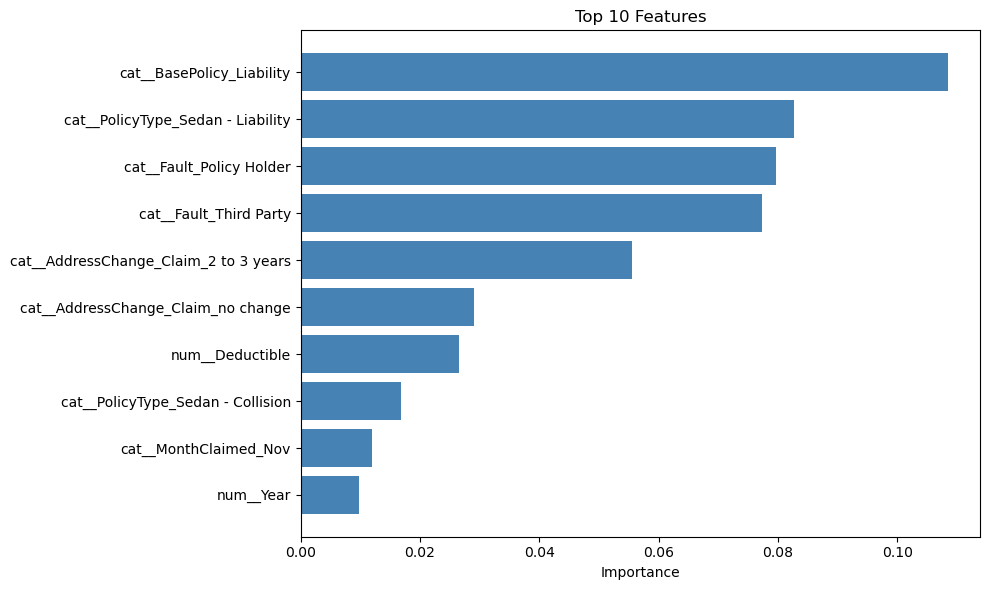

In [24]:
feature_names = best_model.named_steps['prep'].get_feature_names_out()
importances = best_model.named_steps['model'].feature_importances_

feat_imp = (pd.DataFrame({'feature': feature_names, 'importance': importances})
            .sort_values('importance', ascending=False)
            .reset_index(drop=True))

# top 10
top10 = feat_imp.head(10).iloc[::-1]
plt.figure(figsize=(10, 6))
plt.barh(top10['feature'], top10['importance'], color='steelblue')
plt.xlabel('Importance')
plt.title('Top 10 Features')
plt.tight_layout()
plt.savefig('outputs/feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

# liability policies + fault (policy holder / third party) + address change on top - makes sense for staged accidents
# one-hot splits importance across columns, so read it as directional

ROC curve + threshold tradeoff

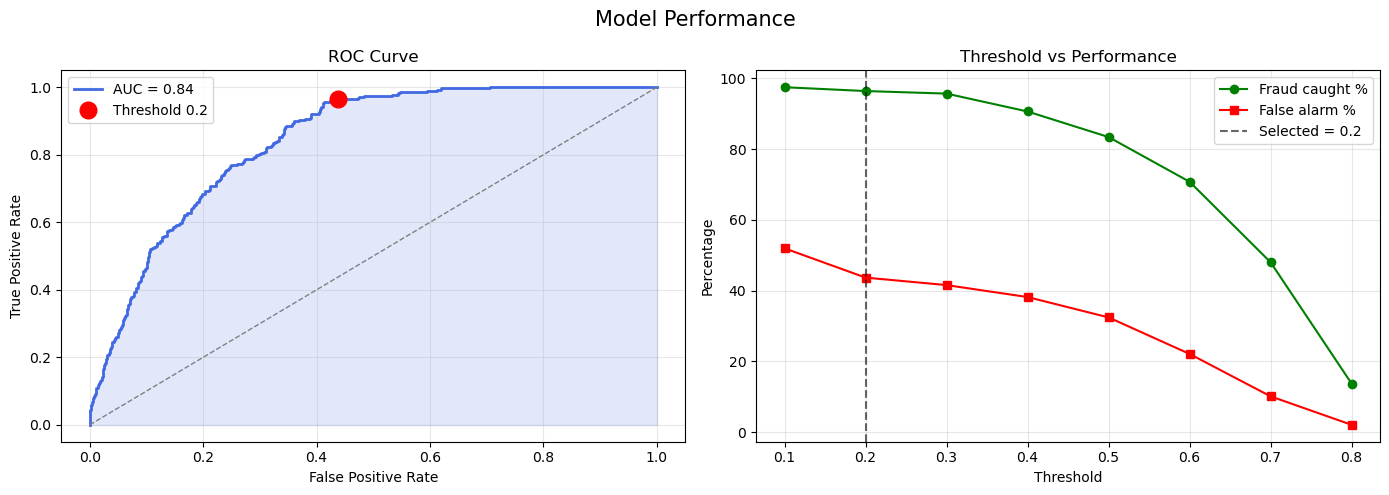

In [25]:
fpr_curve, tpr_curve, _ = roc_curve(y_test, y_pred_proba)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(fpr_curve, tpr_curve, lw=2, color='royalblue', label=f'AUC = {roc_auc:.2f}')
axes[0].fill_between(fpr_curve, tpr_curve, alpha=0.15, color='royalblue')
axes[0].plot([0, 1], [0, 1], lw=1, color='gray', linestyle='--')
axes[0].plot(false_alarm, fraud_caught, 'ro', markersize=12, label=f'Threshold {threshold}')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(eval_summary['threshold'], eval_summary['fraud_caught'] * 100,
             marker='o', label='Fraud caught %', color='green')
axes[1].plot(eval_summary['threshold'], eval_summary['false_alarm_rate'] * 100,
             marker='s', label='False alarm %', color='red')
axes[1].axvline(threshold, color='black', linestyle='--', alpha=0.6, label=f'Selected = {threshold}')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('Percentage')
axes[1].set_title('Threshold vs Performance')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Model Performance', fontsize=15)
plt.tight_layout()
plt.savefig('outputs/roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()

Confusion matrix

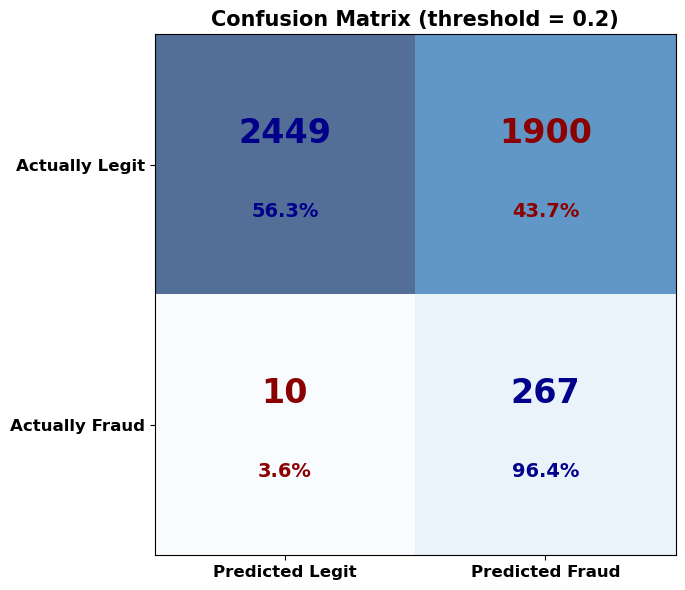

In [26]:
fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
im = ax.imshow(cm, cmap='Blues', alpha=0.7)

for i in range(2):
    for j in range(2):
        val = cm[i, j]
        pct = val / cm[i].sum() * 100
        # blue = correct (diagonal), red = errors
        color = 'darkblue' if i == j else 'darkred'
        ax.text(j, i - 0.12, f'{val}', ha='center', va='center',
                fontsize=24, fontweight='bold', color=color)
        ax.text(j, i + 0.18, f'{pct:.1f}%', ha='center', va='center',
                fontsize=14, fontweight='bold', color=color)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Predicted Legit', 'Predicted Fraud'], fontsize=12, fontweight='bold')
ax.set_yticklabels(['Actually Legit', 'Actually Fraud'], fontsize=12, fontweight='bold')
ax.set_title(f'Confusion Matrix (threshold = {threshold})', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

Cost analysis
- assumptions: $15K avg fraud payout, $250 per investigation
- simulated on the held-out test set only - not an annual figure
- 100% of flagged fraud assumed stopped (optimistic - real investigations won't catch everything)
- 'no model' is a weak baseline here - compare against investigating everything below

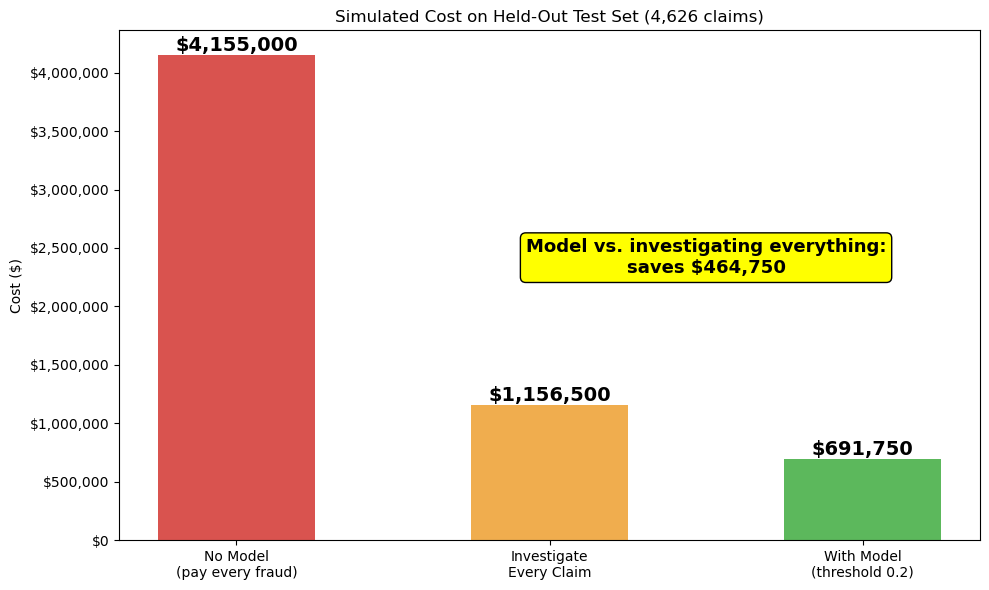

No model (pay every fraud): $4,155,000
Investigate every claim:    $1,156,500
With model:                 $691,750
Model vs no model:          saves $3,463,250 (83.4% reduction)
Model vs investigate all:   saves $464,750 ($100 per claim)


In [27]:
cost_no_model = (tp + fn) * AVG_FRAUD
 
# investigate every claim (no model): catches all the fraud but pays for every investigation
cost_investigate_all = len(y_test) * INVESTIGATION
 
# with model: missed fraud still gets paid, everything flagged gets investigated
cost_with_model = (fn * AVG_FRAUD) + ((tp + fp) * INVESTIGATION)
 
savings = cost_no_model - cost_with_model
savings_vs_investigate_all = cost_investigate_all - cost_with_model
 
fig, ax = plt.subplots(figsize=(10, 6))
labels = ['No Model\n(pay every fraud)', 'Investigate\nEvery Claim', f'With Model\n(threshold {threshold})']
costs = [cost_no_model, cost_investigate_all, cost_with_model]
bars = ax.bar(labels, costs, color=['#d9534f', '#f0ad4e', '#5cb85c'], width=0.5)
 
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f'${bar.get_height():,.0f}', ha='center', va='bottom',
            fontsize=14, fontweight='bold')
 
# the comparison that matters - model vs just investigating everything
ax.text(1.5, cost_no_model * 0.55, f'Model vs. investigating everything:\nsaves ${savings_vs_investigate_all:,.0f}',
        ha='center', fontsize=13, fontweight='bold', bbox=dict(boxstyle='round', facecolor='yellow'))
 
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))
ax.set_ylabel('Cost ($)')
ax.set_title(f'Simulated Cost on Held-Out Test Set ({len(y_test):,} claims)')
plt.tight_layout()
plt.savefig('outputs/cost_analysis.png', dpi=300, bbox_inches='tight')
plt.show()
 
print(f"No model (pay every fraud): ${cost_no_model:,.0f}")
print(f"Investigate every claim:    ${cost_investigate_all:,.0f}")
print(f"With model:                 ${cost_with_model:,.0f}")
print(f"Model vs no model:          saves ${savings:,.0f} ({savings / cost_no_model:.1%} reduction)")
print(f"Model vs investigate all:   saves ${savings_vs_investigate_all:,.0f} (${savings_vs_investigate_all / len(y_test):,.0f} per claim)")


Baseline + lift
- baseline: investigate every claim, no model - at $250 vs $15K, break-even precision is only 1.7% so this is a strong baseline
- lift: if you can only review the top x% of claims, how much fraud do you catch?

In [28]:
# baseline - investigate every claim, no model
savings_all = cost_no_model - (len(y_test) * INVESTIGATION)
print(f"Investigate everything: saves ${savings_all:,.0f}")
print(f"Model at {threshold}: saves ${savings:,.0f} (${savings - savings_all:,.0f} more, ${(savings - savings_all) / len(y_test):,.0f} per claim)")
print(f"Model at {capacity_threshold}: saves ${summarize(capacity_threshold)['savings']:,.0f}")

# 0.7 is worse than investigating everything - fine as a capacity cut, not as a cost cut

# lift - rank test claims by predicted risk, check how much fraud sits in the top x%
rank = pd.DataFrame({'proba': y_pred_proba, 'fraud': y_test.values}).sort_values('proba', ascending=False).reset_index(drop=True)
for pct in [0.05, 0.10, 0.20, 0.30]:
    k = int(len(rank) * pct)
    caught = rank['fraud'][:k].sum() / rank['fraud'].sum()
    print(f"Top {pct:.0%} of claims: catches {caught:.1%} of fraud ({caught / pct:.1f}x lift)")

Investigate everything: saves $2,998,500
Model at 0.2: saves $3,463,250 ($464,750 more, $100 per claim)
Model at 0.7: saves $1,851,500
Top 5% of claims: catches 23.1% of fraud (4.6x lift)
Top 10% of claims: catches 39.7% of fraud (4.0x lift)
Top 20% of claims: catches 62.8% of fraud (3.1x lift)
Top 30% of claims: catches 77.6% of fraud (2.6x lift)


How noisy are these numbers?
- only 277 fraud cases in the test set, so one split can swing a fair bit
- resampling the test claims 1,000 times to get a rough 95% range on AUC and lift
- 95% range = where the number should land about 95% of the time if the test set had been a different draw

In [29]:
rng = np.random.default_rng(42)
y_arr = y_test.values
boot_auc, boot_lift10, boot_lift5 = [], [], []

for _ in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    yb, pb = y_arr[idx], y_pred_proba[idx]
    boot_auc.append(roc_auc_score(yb, pb))
    order = np.argsort(-pb)
    for pct, store in [(0.10, boot_lift10), (0.05, boot_lift5)]:
        k = int(len(yb) * pct)
        store.append((yb[order[:k]].sum() / yb.sum()) / pct)

def ci(x):
    return np.percentile(x, 2.5), np.percentile(x, 97.5)

print(f"Test AUC {roc_auc:.3f}: 95% range {ci(boot_auc)[0]:.3f} to {ci(boot_auc)[1]:.3f}")
print(f"Top 10% lift: 95% range {ci(boot_lift10)[0]:.1f}x to {ci(boot_lift10)[1]:.1f}x")
print(f"Top 5% lift:  95% range {ci(boot_lift5)[0]:.1f}x to {ci(boot_lift5)[1]:.1f}x")

# only captures test-set noise (which claims landed in the 30%) - the model isn't refit
# ranges are roughly +/- 0.5x on the lift - 4.0x is not a precise number

Test AUC 0.842: 95% range 0.823 to 0.859
Top 10% lift: 95% range 3.5x to 4.5x
Top 5% lift:  95% range 3.8x to 5.5x


Does it hold up on a later year?
- the random split mixes 1994-96 together - real use is scoring claims that come after the training data
- train on 1994-95, test on 1996 (xgb_v2 settings, same as the final model)
- year is dropped here - it can't mean anything for claims from a later year

In [30]:
X_time = df.drop(['FraudFound_P'] + DROP_COLS + ['Year'], axis=1)
y_time = df['FraudFound_P']
tr = (df['Year'] <= 1995).values
te = (df['Year'] == 1996).values

# own class ratio for the 1994-95 training rows
spw_time = (y_time[tr] == 0).sum() / (y_time[tr] == 1).sum()
time_model = Pipeline([
    ('prep', make_preprocess(X_time[tr])),
    ('model', XGBClassifier(**xgb_v2, scale_pos_weight=spw_time))
])
time_model.fit(X_time[tr], y_time[tr])
p_time = time_model.predict_proba(X_time[te])[:, 1]

y_te = y_time[te].values
auc_time = roc_auc_score(y_te, p_time)
print(f"Train 1994-95: {tr.sum()} claims | Test 1996: {te.sum()} claims, {y_te.sum()} fraud")
print(f"1996 AUC: {auc_time:.3f}  (random-split test AUC was {roc_auc:.3f})")

order = np.argsort(-p_time)
for pct in [0.05, 0.10, 0.20]:
    k = int(len(y_te) * pct)
    caught = y_te[order[:k]].sum() / y_te.sum()
    print(f"Top {pct:.0%} of 1996 claims: catches {caught:.1%} of fraud ({caught / pct:.1f}x lift)")

# fewer fraud cases here (1996 only) so this is noisier than the main test set - read it as a direction, not a precise number
# big drop from the random split - random split puts claims from the same stretch of time in both train and test, a later year is the harder (more realistic) test
# still only 213 fraud cases so the exact numbers are noisy, but the direction is clear

Train 1994-95: 11337 claims | Test 1996: 4083 claims, 213 fraud
1996 AUC: 0.759  (random-split test AUC was 0.842)
Top 5% of 1996 claims: catches 9.9% of fraud (2.0x lift)
Top 10% of 1996 claims: catches 17.4% of fraud (1.7x lift)
Top 20% of 1996 claims: catches 39.4% of fraud (2.0x lift)


Final Numbers

In [31]:
caught10 = rank['fraud'][:int(len(rank) * 0.10)].sum() / rank['fraud'].sum()
caught5 = rank['fraud'][:int(len(rank) * 0.05)].sum() / rank['fraud'].sum()

print(f"Top 10% reviewed:   catches {caught10:.1%} of fraud ({caught10 / 0.10:.1f}x lift, 95% range {ci(boot_lift10)[0]:.1f}x-{ci(boot_lift10)[1]:.1f}x)")
print(f"Top 5% reviewed:    catches {caught5:.1%} of fraud ({caught5 / 0.05:.1f}x lift, 95% range {ci(boot_lift5)[0]:.1f}x-{ci(boot_lift5)[1]:.1f}x)")
print(f"Test AUC:           {roc_auc:.3f} (95% range {ci(boot_auc)[0]:.3f}-{ci(boot_auc)[1]:.3f})")
print(f"CV AUC:             {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")
print(f"1996-only AUC:      {auc_time:.3f} (train 1994-95, year dropped)")
print()
print(f"Threshold:          {threshold} (picked on out-of-fold train predictions)")
print(f"Fraud caught:       {fraud_caught:.1%} ({tp}/{tp+fn})")
print(f"Precision:          {precision:.1%}")
print(f"Claims flagged:     {(tp + fp) / len(y_test):.1%} of test claims")
print(f"Simulated savings:  ${savings:,.0f} on {len(y_test):,} held-out claims ({savings / cost_no_model:.1%} reduction)")
print(f"Assumptions:        ${AVG_FRAUD:,} per fraud payout, ${INVESTIGATION} per investigation")

Top 10% reviewed:   catches 39.7% of fraud (4.0x lift, 95% range 3.5x-4.5x)
Top 5% reviewed:    catches 23.1% of fraud (4.6x lift, 95% range 3.8x-5.5x)
Test AUC:           0.842 (95% range 0.823-0.859)
CV AUC:             0.827 (+/- 0.011)
1996-only AUC:      0.759 (train 1994-95, year dropped)

Threshold:          0.2 (picked on out-of-fold train predictions)
Fraud caught:       96.4% (267/277)
Precision:          12.3%
Claims flagged:     46.8% of test claims
Simulated savings:  $3,463,250 on 4,626 held-out claims (83.4% reduction)
Assumptions:        $15,000 per fraud payout, $250 per investigation
